# Plot stability phase diagram from NPZ data

只需要在下面的参数区输入 `S_VALUE` 和 `BETA`。Notebook 会自动从
`linear_regression/results_autodl_722` 中找到对应数据文件并画图。

例如 `S_VALUE = 3, BETA = 1.5` 会读取 `beta1_5s3.npz`；同时兼容现有的无扩展名 NPZ 文件。


In [ ]:
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt

# ======================== 只需要修改这里 ========================
S_VALUE = 3
BETA = 1.5
# ===============================================================

# 数据目录。优先按 notebook 所在项目结构定位；若当前工作目录是项目根目录，
# 下面的候选路径也可以直接工作。
_DATA_DIR_CANDIDATES = [
    Path.cwd().parent / 'results_autodl_722',       # 从 linear_regression/gpu 运行
    Path.cwd() / 'linear_regression' / 'results_autodl_722',  # 从项目根目录运行
    Path.cwd() / 'results_autodl_722',              # 从 linear_regression 运行
]
DATA_DIR = next((path.resolve() for path in _DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    searched = '\n'.join(f'  - {path.resolve()}' for path in _DATA_DIR_CANDIDATES)
    raise FileNotFoundError(f'找不到 results_autodl_722 数据目录，已检查：\n{searched}')


def number_tag(value, name):
    """把 1.5 -> '1_5'、3 -> '3'，用于构造数据文件名。"""
    try:
        value = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f'{name} 必须是数值，当前为 {value!r}') from exc
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f'{name} 必须是正的有限数，当前为 {value!r}')
    return format(value, '.15g').replace('.', '_')


# 根据输入的 beta 和 s 自动定位：
#   beta2s3.npz / beta1_5s3.npz
# 并兼容当前目录里没有 .npz 后缀、但内容仍是 NPZ 的文件。
file_stem = f'beta{number_tag(BETA, "BETA")}s{number_tag(S_VALUE, "S_VALUE")}'
candidates = [DATA_DIR / f'{file_stem}.npz', DATA_DIR / file_stem]
NPZ_PATH = next((path for path in candidates if path.is_file()), None)

if NPZ_PATH is None:
    available = sorted(
        path.name for path in DATA_DIR.iterdir()
        if path.is_file() and path.name.lower().startswith('beta')
    )
    available_text = ', '.join(available) if available else '（没有找到 beta*s* 数据文件）'
    raise FileNotFoundError(
        f'找不到 beta={BETA:g}, s={S_VALUE:g} 对应的数据文件。\n'
        f'尝试过：{candidates[0].name} 和 {candidates[1].name}\n'
        f'当前可用文件：{available_text}'
    )

print(f'数据目录: {DATA_DIR}')
print(f'输入参数: beta={BETA:g}, s={S_VALUE:g}')
print(f'读取文件: {NPZ_PATH.name}')


In [17]:
# allow_pickle=True 是必需的，因为原 notebook 将各算法结果保存为 Python dict。
with np.load(NPZ_PATH, allow_pickle=True) as data:
    print('NPZ fields:', data.files)

    if 'stable' not in data.files:
        raise KeyError(f'{NPZ_PATH} 中缺少绘图必需字段 stable')

    STABLE = data['stable'].item()

    # 数据文件中使用 HB 表示 Polyak heavy-ball；绘图中统一显示为 Polyak。
    if 'Polyak' not in STABLE and 'HB' in STABLE:
        STABLE['Polyak'] = STABLE.pop('HB')

    # 新缓存包含这些元数据；旧缓存若缺少，则使用原 notebook 的网格设置。
    B_LIST = (
        np.asarray(data['B_LIST'], dtype=int)
        if 'B_LIST' in data.files
        else np.rint(2 ** np.arange(0, 13)).astype(int)
    )
    ETA_GRID = (
        np.asarray(data['ETA_GRID'], dtype=float)
        if 'ETA_GRID' in data.files
        else np.logspace(np.log10(2 ** -10), np.log10(8), 50)
    )
    N_SEEDS = (
        int(np.asarray(data['N_SEEDS']).item())
        if 'N_SEEDS' in data.files
        else int(next(iter(STABLE.values())).shape[0])
    )

ALGOS = tuple(name for name in ('SGD', 'Polyak', 'Nesterov') if name in STABLE)
missing = {'SGD', 'Polyak', 'Nesterov'} - set(ALGOS)
if missing:
    raise KeyError(f'stable 字典中缺少算法: {sorted(missing)}')

ONE_MINUS_RHO = 2 ** -24

# 检查数组维度是否与坐标网格匹配。
for name in ALGOS:
    expected = (N_SEEDS, len(ETA_GRID), len(B_LIST))
    if STABLE[name].shape != expected:
        raise ValueError(
            f'{name} 的 stable shape={STABLE[name].shape}，'
            f'但根据元数据预期为 {expected}'
        )

B_EXPONENTS = np.rint(np.log2(B_LIST)).astype(int)
print(f'algorithms={ALGOS}')
print(f'N_SEEDS={N_SEEDS}, B points={len(B_LIST)}, eta points={len(ETA_GRID)}')


NPZ fields: ['stable', 'final_ma', 'final_loss', 'steps_done', 'min_final_ma', 'min_final_ma_eta', 'min_final_loss', 'min_final_loss_eta', 'B_LIST', 'ETA_GRID', 'N_SEEDS']
algorithms=('SGD', 'Polyak', 'Nesterov')
N_SEEDS=5, B points=13, eta points=50


In [18]:
def max_stable_eta_per_seed(stable_cube):
    """返回每个 seed、每个 B 的最大稳定 eta；没有稳定点时为 NaN。"""
    stable_cube = np.asarray(stable_cube, dtype=bool)
    out = np.full((stable_cube.shape[0], stable_cube.shape[2]), np.nan)
    for seed_idx in range(stable_cube.shape[0]):
        for b_idx in range(stable_cube.shape[2]):
            stable_eta_indices = np.flatnonzero(stable_cube[seed_idx, :, b_idx])
            if stable_eta_indices.size:
                out[seed_idx, b_idx] = ETA_GRID[stable_eta_indices[-1]]
    return out


def mean_max_stable_eta(stable_cube):
    """对各 seed 的最大稳定 eta 求平均。"""
    per_seed = max_stable_eta_per_seed(stable_cube)
    out = np.full(per_seed.shape[1], np.nan)
    for b_idx in range(per_seed.shape[1]):
        values = per_seed[:, b_idx]
        values = values[np.isfinite(values)]
        if values.size:
            out[b_idx] = values.mean()
    return out


def fit_prefactor(boundary, power, indices=None):
    """在对数尺度拟合 eta ≈ C * B**power * (1-rho) 中的 C。"""
    boundary = np.asarray(boundary, dtype=float)
    indices = np.arange(len(boundary)) if indices is None else np.asarray(indices, dtype=int)
    selected_boundary = boundary[indices]
    selected_B = B_LIST[indices].astype(float)
    mask = np.isfinite(selected_boundary) & (selected_boundary > 0)
    if not np.any(mask):
        return 1.0
    denominator = selected_B[mask] ** power * ONE_MINUS_RHO
    return float(np.exp(np.mean(np.log(selected_boundary[mask] / denominator))))


def fit_horizontal_level(boundary, indices=None):
    """在对数尺度用几何平均拟合水平线。"""
    boundary = np.asarray(boundary, dtype=float)
    indices = np.arange(len(boundary)) if indices is None else np.asarray(indices, dtype=int)
    selected_boundary = boundary[indices]
    mask = np.isfinite(selected_boundary) & (selected_boundary > 0)
    if not np.any(mask):
        return 1.0
    return float(np.exp(np.mean(np.log(selected_boundary[mask]))))


## 绘图设置

下面的设置沿用原 notebook。可直接修改拟合线偏移、Nesterov 分段点数、虚线延长比例和横坐标范围。


In [19]:
# 标题、坐标轴文字、刻度标签和图例文字的放大倍数。
TEXT_SCALE = 1.5

# 拟合线纵向缩放：1.0 表示不移动。
Polyak_FIT_SHIFT = 1.0
NESTEROV_POWER_SHIFT = 1.0
NESTEROV_FLAT_SHIFT = 1.0

# 明确指定 Nesterov 两段拟合分别使用哪些 batch size B。
# 列表中的 B 必须存在于数据的 B_LIST 中。
NESTEROV_POWER_FIT_B = [1,2,4, 8,16]
NESTEROV_FLAT_FIT_B = [32,64,128, 256, 512, 1024, 2048, 4096]

# 两段虚线向另一段延伸的比例。
NESTEROV_POWER_EXTENSION_RATIO = 1 / 16
NESTEROV_FLAT_EXTENSION_RATIO = 1 / 7
DRAW_NESTEROV_SPLIT_LINE = True

# 横坐标显示范围（batch size B）。
# 例如下面表示显示 2^0 到 2^10；可直接修改为其他正数范围。
X_DISPLAY_MIN = 2 ** 2
X_DISPLAY_MAX = 2 ** 10

if X_DISPLAY_MIN <= 0 or X_DISPLAY_MAX <= X_DISPLAY_MIN:
    raise ValueError('横坐标范围必须满足 0 < X_DISPLAY_MIN < X_DISPLAY_MAX。')

# 输出文件；设为 None 时保存到当前工作目录，不向数据目录写文件。
PDF_PATH = None


In [20]:
styles = {
    'SGD': {
        'color': 'tab:green',
        'marker': '^',
    },
    'Polyak': {
        'color': 'tab:blue',
        'marker': 'o',
        'power': 1.0,
        'theory_label': r'Polyak fit: $\eta \propto B(1-\rho)$',
    },
    'Nesterov': {
        'color': 'tab:orange',
        'marker': 's',
        'power': BETA,
        'theory_label_power': (
            rf'Nesterov fit: $\eta \propto B^{{\beta}}(1-\rho)$, '
            rf'$\beta={BETA:g}$, $s={S_VALUE:g}$'
        ),
        'theory_label_flat': r'Nesterov large-$B$ horizontal fit',
    },
}

BOUNDARIES = {}
PER_SEED_BOUNDARIES = {}
REFS = {}

for name in ALGOS:
    PER_SEED_BOUNDARIES[name] = max_stable_eta_per_seed(STABLE[name])
    BOUNDARIES[name] = mean_max_stable_eta(STABLE[name])

# Polyak：所有有效点拟合固定斜率 1 的参考线。
Polyak_C = fit_prefactor(BOUNDARIES['Polyak'], styles['Polyak']['power']) * Polyak_FIT_SHIFT
REFS['Polyak'] = Polyak_C * B_LIST.astype(float) ** styles['Polyak']['power'] * ONE_MINUS_RHO

# Nesterov：用设置中明确给出的 B 值分别拟合幂律段和水平段。
num_B = len(B_LIST)
if num_B < 2:
    raise ValueError('Nesterov 分段拟合至少需要两个 batch-size 点。')


def B_values_to_indices(selected_B, setting_name):
    """将设置中的 B 值转换为 B_LIST 索引，并检查其有效性。"""
    selected_B = np.asarray(selected_B, dtype=int)
    if selected_B.size == 0:
        raise ValueError(f'{setting_name} 不能为空。')
    if np.unique(selected_B).size != selected_B.size:
        raise ValueError(f'{setting_name} 中不能包含重复的 B。')

    missing_B = selected_B[~np.isin(selected_B, B_LIST)]
    if missing_B.size:
        raise ValueError(
            f'{setting_name} 中的 B={missing_B.tolist()} 不存在于数据 B_LIST 中；'
            f'可选值为 {B_LIST.tolist()}'
        )
    return np.array([np.flatnonzero(B_LIST == B)[0] for B in selected_B], dtype=int)


power_fit_indices = B_values_to_indices(
    NESTEROV_POWER_FIT_B,
    'NESTEROV_POWER_FIT_B',
)
flat_fit_indices = B_values_to_indices(
    NESTEROV_FLAT_FIT_B,
    'NESTEROV_FLAT_FIT_B',
)

if np.intersect1d(power_fit_indices, flat_fit_indices).size:
    raise ValueError('幂律拟合和水平拟合使用的 B 不能重叠。')
if np.max(power_fit_indices) >= np.min(flat_fit_indices):
    raise ValueError('幂律拟合使用的 B 必须全部小于水平拟合使用的 B。')

# 分段位置取水平拟合列表中最小 B 的位置。
split_index = int(np.min(flat_fit_indices))
power_segment_indices = np.arange(0, split_index)
flat_segment_indices = np.arange(split_index, num_B)

nesterov_boundary = BOUNDARIES['Nesterov']
nesterov_power_C = (
    fit_prefactor(
        nesterov_boundary,
        styles['Nesterov']['power'],
        power_fit_indices,
    )
    * NESTEROV_POWER_SHIFT
)
nesterov_power_ref = (
    nesterov_power_C
    * B_LIST.astype(float) ** styles['Nesterov']['power']
    * ONE_MINUS_RHO
)

nesterov_flat_level = (
    fit_horizontal_level(nesterov_boundary, flat_fit_indices)
    * NESTEROV_FLAT_SHIFT
)
nesterov_flat_ref = np.full(num_B, nesterov_flat_level, dtype=float)

REFS['Nesterov'] = np.empty(num_B, dtype=float)
REFS['Nesterov'][power_segment_indices] = nesterov_power_ref[power_segment_indices]
REFS['Nesterov'][flat_segment_indices] = nesterov_flat_ref[flat_segment_indices]

power_extension = int(
    np.ceil(len(flat_segment_indices) * NESTEROV_POWER_EXTENSION_RATIO)
)
power_plot_end = min(split_index + power_extension, num_B)
power_plot_indices = np.arange(0, power_plot_end)

flat_extension = int(
    np.ceil(len(power_segment_indices) * NESTEROV_FLAT_EXTENSION_RATIO)
)
flat_plot_start = max(split_index - flat_extension, 0)
flat_plot_indices = np.arange(flat_plot_start, num_B)


saved PDF to /Users/audenhuang/Desktop/momentum/Momentum_scaling/linear_regression/gpu/beta2s3_plot.pdf


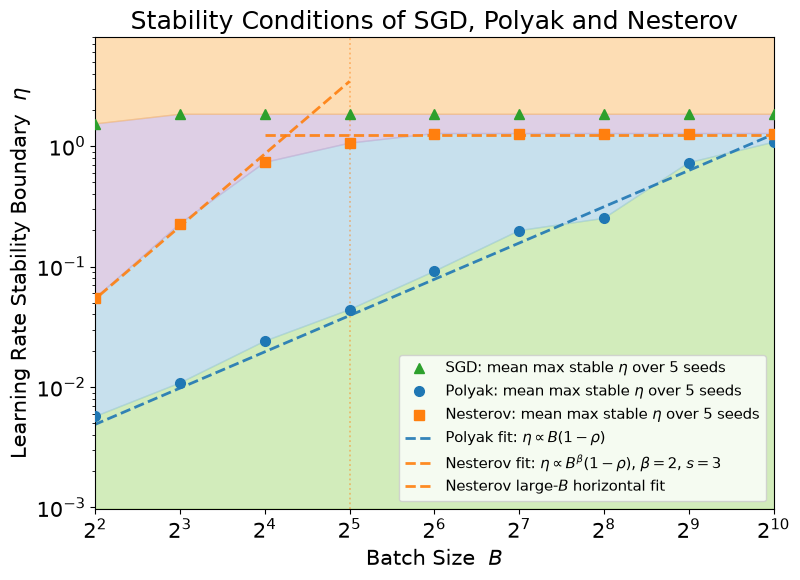

In [21]:
fig, ax = plt.subplots(figsize=(8.1, 5.9))

eta_low = float(np.min(ETA_GRID))
eta_high = float(np.max(ETA_GRID))

# 缺失的经验边界点分别用下界或拟合参考线替代，以便完成区域填色。
sgd_region = np.where(np.isfinite(BOUNDARIES['SGD']), BOUNDARIES['SGD'], eta_low)
Polyak_region = np.where(np.isfinite(BOUNDARIES['Polyak']), BOUNDARIES['Polyak'], REFS['Polyak'])
nes_region = np.where(
    np.isfinite(BOUNDARIES['Nesterov']),
    BOUNDARIES['Nesterov'],
    REFS['Nesterov'],
)

sgd_region = np.clip(sgd_region, eta_low, eta_high)
Polyak_region = np.clip(Polyak_region, eta_low, eta_high)
nes_region = np.clip(nes_region, eta_low, eta_high)

# 每个 B 处按边界高度排序，避免边界交叉造成填色覆盖错误。
# 四个填色区域使用 _nolegend_，不显示在图例中。
bands = np.sort(np.vstack([sgd_region, Polyak_region, nes_region]), axis=0)
band_low, band_mid, band_high = bands

ax.fill_between(B_LIST, eta_low, band_low, color='#b2df8a', alpha=0.58,
                label='_nolegend_', zorder=0)
ax.fill_between(B_LIST, band_low, band_mid, color='#a6cee3', alpha=0.62,
                label='_nolegend_', zorder=0)
ax.fill_between(B_LIST, band_mid, band_high, color='#cab2d6', alpha=0.62,
                label='_nolegend_', zorder=0)
ax.fill_between(B_LIST, band_high, eta_high, color='#fdbf6f', alpha=0.52,
                label='_nolegend_', zorder=0)

# 实验稳定性边界：只画彩色标记，不连接折线。
for name in ALGOS:
    boundary = BOUNDARIES[name]
    mask = np.isfinite(boundary) & (boundary > 0)
    ax.plot(
        B_LIST[mask], boundary[mask],
        color=styles[name]['color'],
        marker=styles[name]['marker'],
        linestyle='None',
        markersize=7.0,
        label=rf'{name}: mean max stable $\eta$ over {N_SEEDS} seeds',
        zorder=3,
    )

# Polyak 与 Nesterov 拟合线。
ax.plot(B_LIST, REFS['Polyak'], '--', color=styles['Polyak']['color'], alpha=0.9,
        linewidth=2.0, label=styles['Polyak']['theory_label'], zorder=2)
ax.plot(B_LIST[power_plot_indices], nesterov_power_ref[power_plot_indices], '--',
        color=styles['Nesterov']['color'], alpha=0.9, linewidth=2.0,
        label=styles['Nesterov']['theory_label_power'], zorder=2)
ax.plot(B_LIST[flat_plot_indices], nesterov_flat_ref[flat_plot_indices], '--',
        color=styles['Nesterov']['color'], alpha=0.9, linewidth=2.0,
        label=styles['Nesterov']['theory_label_flat'], zorder=2)

if DRAW_NESTEROV_SPLIT_LINE:
    ax.axvline(B_LIST[split_index], linestyle=':', color=styles['Nesterov']['color'],
               alpha=0.45, linewidth=1.3, zorder=1)

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlim(X_DISPLAY_MIN, X_DISPLAY_MAX)

# 只显示落在横坐标范围内的 2 的整数次幂刻度。
x_tick_min_exponent = int(np.ceil(np.log2(X_DISPLAY_MIN)))
x_tick_max_exponent = int(np.floor(np.log2(X_DISPLAY_MAX)))
x_tick_exponents = np.arange(x_tick_min_exponent, x_tick_max_exponent + 1)
ax.set_xticks(2.0 ** x_tick_exponents)
ax.set_xticklabels([rf'$2^{{{exponent}}}$' for exponent in x_tick_exponents])
ax.set_ylim(eta_low, eta_high)

ax.set_xlabel('Batch Size  $B$', fontsize=10 * TEXT_SCALE)
ax.set_ylabel(r'Learning Rate Stability Boundary  $\eta$', fontsize=10 * TEXT_SCALE)
ax.set_title('Stability Conditions of SGD, Polyak and Nesterov', fontsize=12 * TEXT_SCALE)
ax.tick_params(axis='both', which='major', labelsize=10 * TEXT_SCALE, length=3.5, width=0.8)
ax.tick_params(axis='both', which='minor', length=2.0, width=0.6)
ax.legend(title='', fontsize=7.0 * TEXT_SCALE, title_fontsize=7.5 * TEXT_SCALE, loc='best')

fig.tight_layout()

if PDF_PATH is None:
    PDF_PATH = Path.cwd() / f'{NPZ_PATH.stem}_plot.pdf'
else:
    PDF_PATH = Path(PDF_PATH)
PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(PDF_PATH, bbox_inches='tight')
print(f'saved PDF to {PDF_PATH}')

plt.show()
